# 2.3. Why standard deviation doesn't work

In [72]:
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

%matplotlib inline

# Helper function

In [73]:
# xmr process statistics calculations
def xmr_process_stats(data):
    
    # Calculate mean
    mean = data.mean()
    
    # Calculate the moving range
    mRs = data.diff().abs()
    ave_mR = mRs.mean()

    # Calculate process limits
    UPL = mean + (2.660 * ave_mR)
    LPL = mean - (2.660 * ave_mR)
    URL = 3.268 * ave_mR
    
    return {
        'Mean': mean,
        'Ave. mR': ave_mR,
        'UPL': UPL,
        'LPL': LPL,
        'URL': URL
    }

In [74]:
# Get data 
url = r'https://raw.githubusercontent.com/jimlehner/crash-course-in-variation/refs/heads/main/data/sawtooth_data.csv'

# Get data function
def get_data(dataset_url) -> pd.DataFrame:
    return pd.read_csv(dataset_url)

# Get the data
df = get_data(url)

df['Observation'] = df['Observation'].astype('string')

df.head()

,Observation,Value
0,1,35
1,2,36
2,3,34
3,4,34
4,5,56


# Calculate process statistics

In [75]:
stats = xmr_process_stats(df['Value'])

mean = stats['Mean'].round(1)
UPL = stats['UPL'].round(1)
LPL = max(0, stats['LPL'].round(1))
ave_mR = stats['Ave. mR'].round(1)
URL = stats['URL'].round(1)

# Sigma process limits
std = round(df['Value'].std(), 1)
print(std)

sigma_UPL = round(mean + (3*std), 1)
sigma_LPL = round(mean - (3*std), 1)

print(sigma_LPL)

9.7
12.9


# Create labeled time series

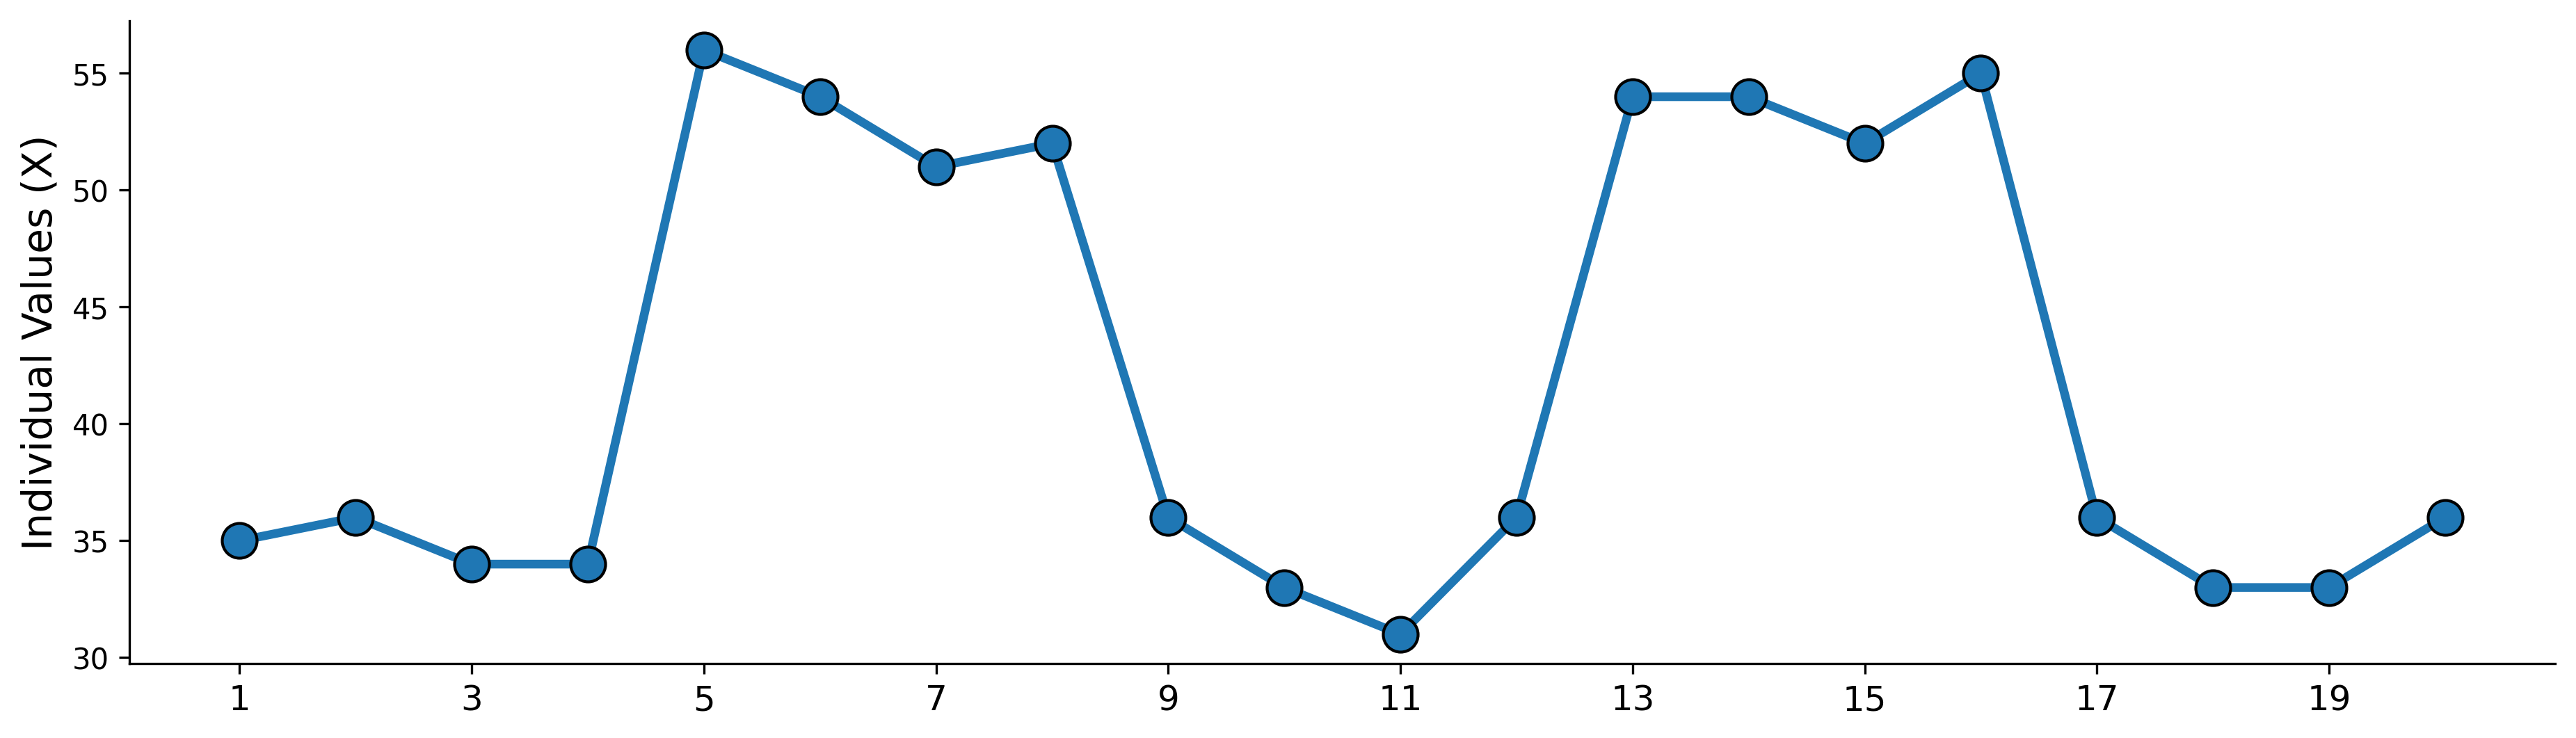

In [76]:
data = df['Value']
labels = df['Observation']

# Create matplotlib figure
fig, axs = plt.subplots(
                       figsize=(15,4),
                       dpi=300)

# Time series
axs.plot(labels, 
            data, 
            marker='o', 
            markersize=12,
            markeredgecolor="black",
            linewidth=3,
            zorder=4)

# Specify xticks for x chart
tick_positions = np.arange(0, len(labels), 2)
axs.set_xticks(tick_positions)
axs.set_xticklabels(
    labels[::2],
    ha='center', 
    fontsize=12
)

annotations = {
    (10.5, 4000, 5, 4100),
    (13.5, 4775, 7, 4775),
    (24.5, 4000, 19, 4100),
    (21.5, 4800, 28, 4800),
    (59.5, 4210, 53, 4100),
    (62.5, 4850, 56, 4850),
}

for x, y, xtext, ytext in annotations:
    axs.annotate(
        'Assignable?',
        xy=(x, y),
        xytext=(xtext, ytext),
        ha='center',
        va='center',
        fontsize=14,
        bbox=dict(
            facecolor='#EDEDED',
            boxstyle='round',
            edgecolor='black'
        ),
        arrowprops=dict(
            color='black'
        ),
        zorder=5
    )

axs.set_ylabel('Individual Values (X)', fontsize=14)

# Despine
sns.despine()
    
plt.show()

# Create XmR chart

In [77]:
# Specify x chart line parameters
xchart_lines = [
    (mean, "-", "black"),
    (UPL, "--", "#d72323"),
    (LPL, "--", "#d72323")
]

# Specify mR chart parameters
sigma_lines = [
    (mean, "-", "black"),
    (sigma_UPL, "--", "#d72323"),
    (sigma_LPL, "--", "#d72323")
]

subplot_titles = [r'$\mathrm{\overline{X}} \pm 2.660\cdot\mathrm{\overline{mR}}$',
                  r'$\mathrm{\overline{X}} \pm 3\cdot s$']

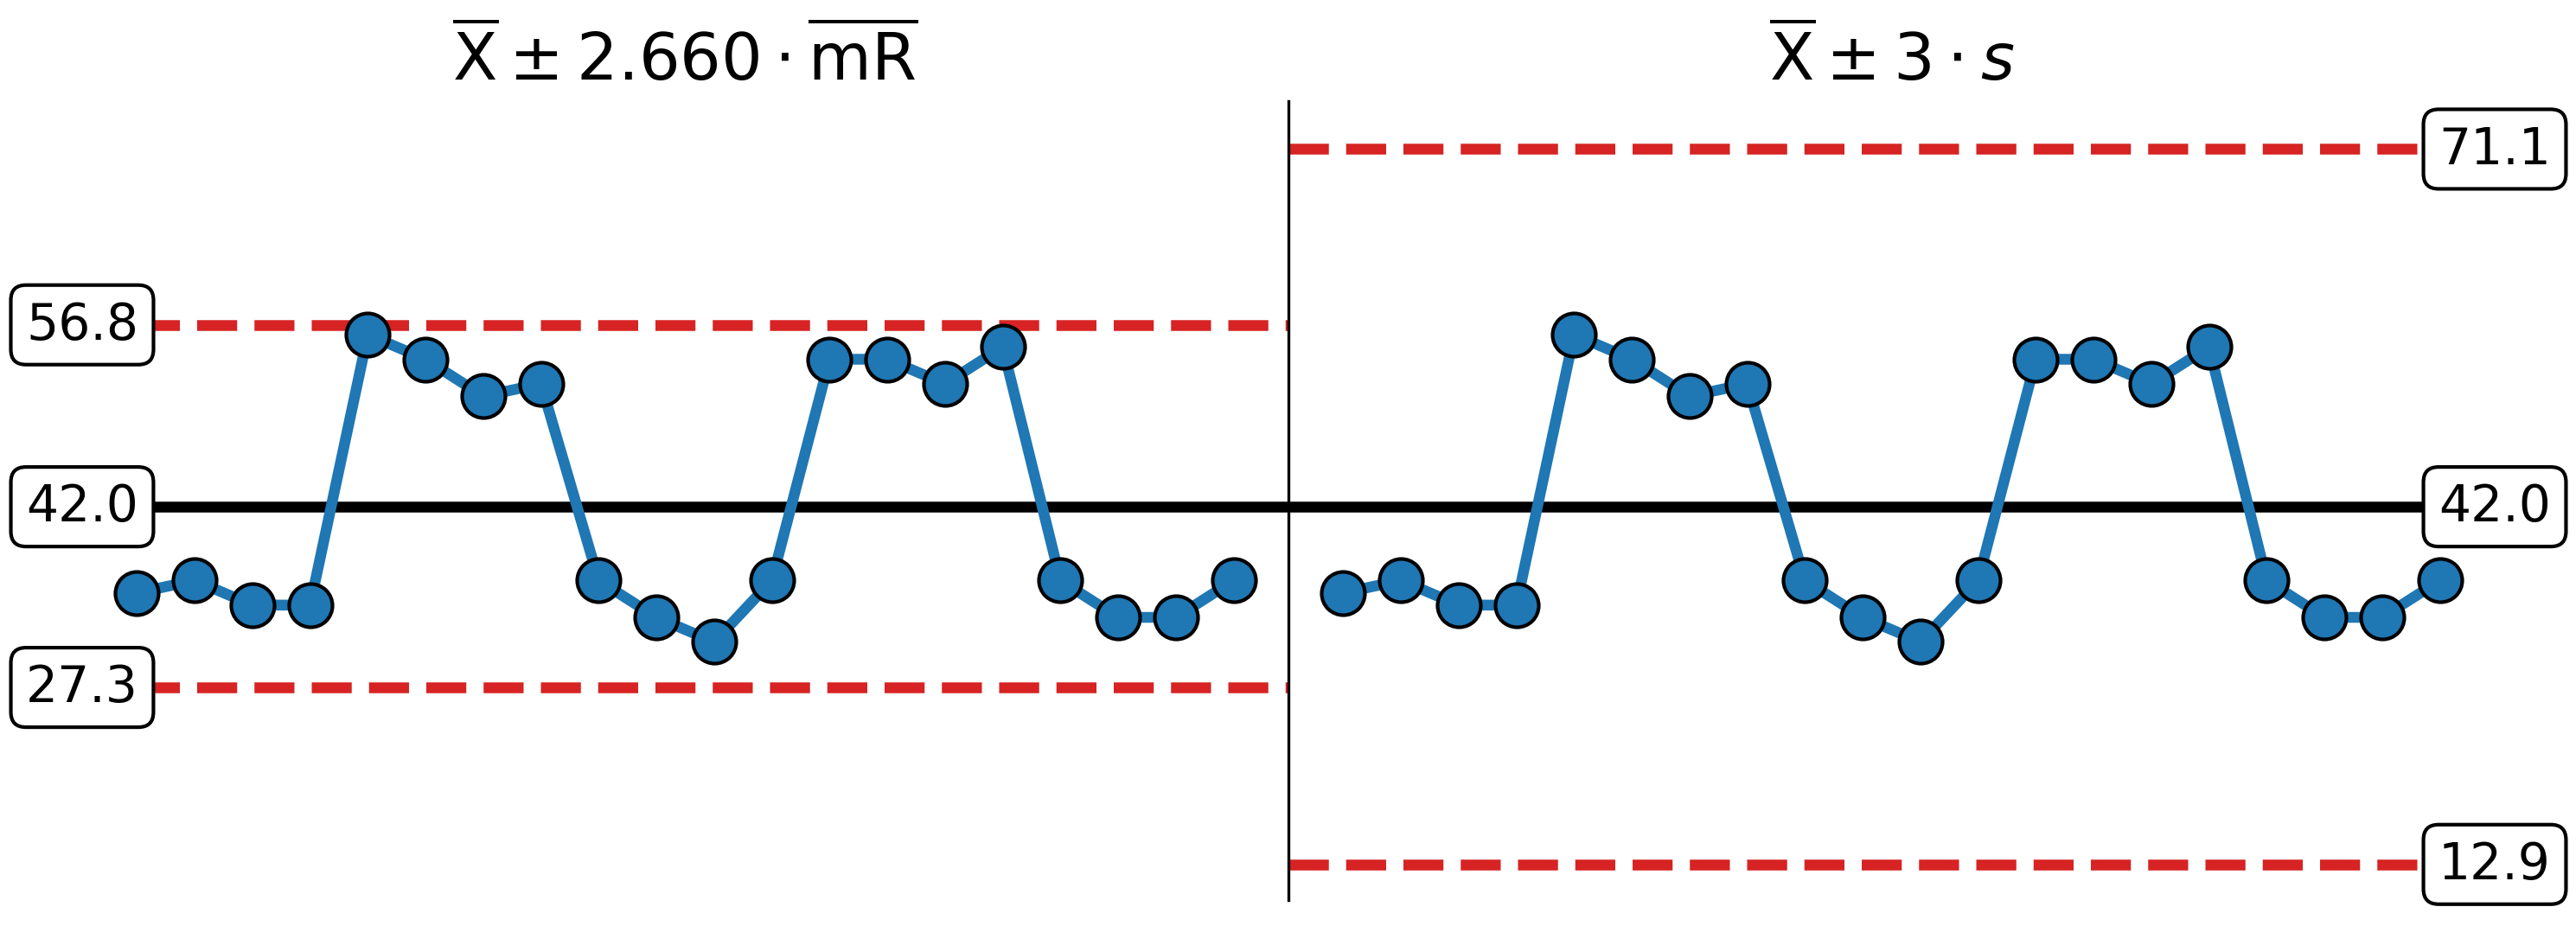

In [78]:
data = df['Value']
mRs = abs(data.diff())
labels = df['Observation']

# Create matplotlib figure
fig, axs = plt.subplots(nrows=1, 
                       ncols=2, 
                       figsize=(12,4),
                        sharey=True,
                       dpi=300)

plt.subplots_adjust(wspace=0)

# X chart
axs[0].plot(labels, 
            data, 
            marker='o', 
            markersize=12,
            markeredgecolor="black",
            linewidth=3,
            zorder=4)

# Specify xticks for x chart
tick_positions = np.arange(0, len(labels), 3)
axs[0].set_xticks(tick_positions)
axs[0].set_xticklabels(labels[::3],
                    ha='center', 
                    fontsize=12)

for value, line_type, color in xchart_lines:
    axs[0].axhline(value, 
                   ls=line_type,
                   linewidth=3,
                   c=color)

# Sigma chart
axs[1].plot(labels,
            data, 
            marker='o', 
            markersize=12,
            markeredgecolor="black",
            linewidth=3,
            zorder=4)

for value, line_type, color in sigma_lines:
    axs[1].axhline(value, 
                   ls=line_type,
                   linewidth=3,
                   c=color)
    
# Offset moving range by one relative to the indivual values
for xi, yi in zip(labels, mRs):
    if np.isnan(yi):
        axs[1].plot(xi, 
                    0, 
                    marker='x', 
                    color='white', 
                    markersize=0) 

# Specify assignable cause condition
above_UPL = data > UPL
below_LPL = data <= LPL
above_URL = mRs > URL

# Highlight observations above UPL
axs[0].plot(
    data[above_UPL],
    marker='o',
    markersize=12,
    markeredgecolor='black',
    markerfacecolor='#d72323',
    linestyle='none',
    zorder=5
)

axs[0].plot(
    data[below_LPL],
    marker='o',
    markersize=12,
    markeredgecolor='black',
    markerfacecolor='#d72323',
    linestyle='none',
    zorder=5
)

        
# Get x limit of subplots
left_xlim = axs[0].get_xlim()[0]
right_xlim = axs[0].get_xlim()[1]
mrlim = axs[1].get_xlim()[1]

# Define annotation values
annotations = [
    (UPL, left_xlim, UPL, axs[0]),
    (LPL, left_xlim, LPL, axs[0]),
    (mean, left_xlim, mean, axs[0]),
    (sigma_UPL, right_xlim, sigma_UPL, axs[1]),
    (sigma_LPL, right_xlim, sigma_LPL, axs[1]),
    (mean, right_xlim, mean, axs[1]),
]
        
# Add central line and process limit annotations
for label, x_pos, y_pos, axis in annotations:
    axis.annotate(label,
                 xy=(x_pos, y_pos), 
                 ha="center", 
                 va="center", 
                 fontsize=14, 
                 bbox=dict(
                     facecolor='white', 
                     boxstyle='round')
                )

# Remove x and y ticks
for ax in axs:
    ax.set_yticks([])
    
# Remove xticks from mR chart
axs[0].set_xticks([])
axs[1].set_xticks([])

axs[0].set_ylim(10, 75)

for i, ax in enumerate(axs):
    ax.set_title(subplot_titles[i], fontsize=18)
 
# Despine
sns.despine(left=True, bottom=True, ax=axs[0])
sns.despine(left=False, bottom=True, ax=axs[1])
    
plt.show()

# Figure 2

In [95]:
# Get data 
url = r'https://raw.githubusercontent.com/jimlehner/crash-course-in-variation/refs/heads/main/data/wafer_thickness.csv'
# Get data function
def get_data(dataset_url) -> pd.DataFrame:
    return pd.read_csv(dataset_url)

# Get the data
wafer_df = get_data(url)

wafer_df['Wafer'] = wafer_df['Wafer'].astype('string')

wafer_df.head()

,Wafer,Average Thickness
0,1,776.74
1,2,774.40
2,3,776.08
3,4,776.62
4,5,775.95


In [99]:
wafer_stats = xmr_process_stats(wafer_df['Average Thickness'])

round_value = 2

wafer_mean = wafer_stats['Mean'].round(round_value)
wafer_UPL = wafer_stats['UPL'].round(round_value)
wafer_LPL = max(0, wafer_stats['LPL'].round(round_value))
wafer_ave_mR = wafer_stats['Ave. mR'].round(round_value)
wafer_URL = wafer_stats['URL'].round(round_value)

# Sigma process limits
wafer_std = round(wafer_df['Average Thickness'].std(), round_value)

wafer_sigma_UPL = round(mean + (3*wafer_std), round_value)
wafer_sigma_LPL = round(mean - (3*wafer_std), round_value)

In [100]:
# Specify x chart line parameters
xchart_lines = [
    (wafer_mean, "-", "black"),
    (wafer_UPL, "--", "#d72323"),
    (wafer_LPL, "--", "#d72323")
]

# Specify mR chart parameters
sigma_lines = [
    (wafer_mean, "-", "black"),
    (wafer_sigma_UPL, "--", "#d72323"),
    (wafer_sigma_LPL, "--", "#d72323")
]

subplot_titles = [r'$\mathrm{\overline{X}} \pm 2.660\cdot\mathrm{\overline{mR}}$',
                  r'$\mathrm{\overline{X}} \pm 3\cdot s$']

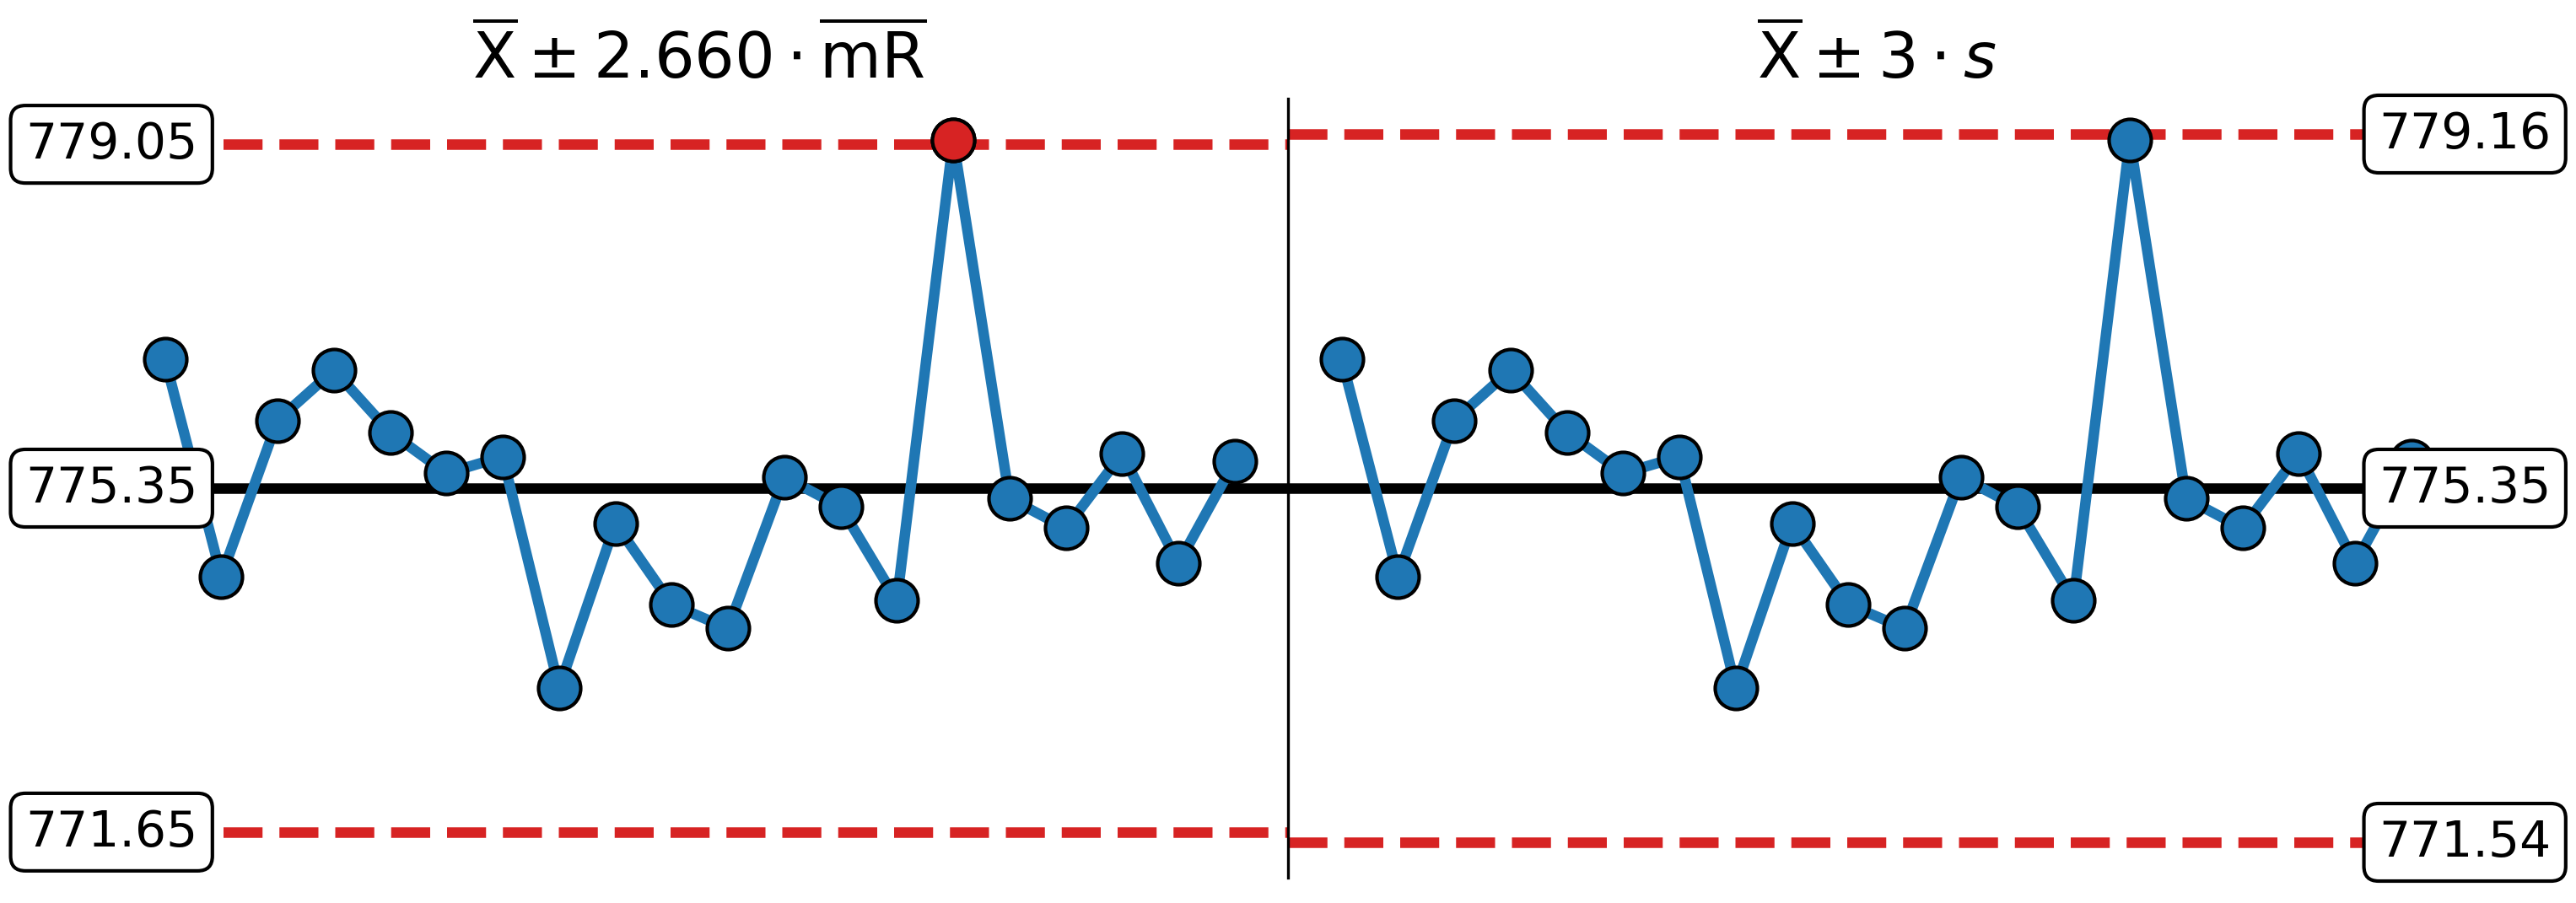

In [108]:
data = wafer_df['Average Thickness']
mRs = abs(data.diff())
labels = wafer_df['Wafer']

# Create matplotlib figure
fig, axs = plt.subplots(nrows=1, 
                       ncols=2, 
                       figsize=(12,4),
                        sharey=True,
                       dpi=300)

plt.subplots_adjust(wspace=0)

# X chart
axs[0].plot(labels, 
            data, 
            marker='o', 
            markersize=12,
            markeredgecolor="black",
            linewidth=3,
            zorder=4)

# Specify xticks for x chart
tick_positions = np.arange(0, len(labels), 3)
axs[0].set_xticks(tick_positions)
axs[0].set_xticklabels(labels[::3],
                    ha='center', 
                    fontsize=12)

for value, line_type, color in xchart_lines:
    axs[0].axhline(value, 
                   ls=line_type,
                   linewidth=3,
                   c=color)

# Sigma chart
axs[1].plot(labels,
            data, 
            marker='o', 
            markersize=12,
            markeredgecolor="black",
            linewidth=3,
            zorder=4)

for value, line_type, color in sigma_lines:
    axs[1].axhline(value, 
                   ls=line_type,
                   linewidth=3,
                   c=color)

# Specify assignable cause condition
above_UPL = data > UPL
below_LPL = data <= LPL
above_URL = mRs > URL

# Highlight observations above UPL
axs[0].plot(
    data[above_UPL],
    marker='o',
    markersize=12,
    markeredgecolor='black',
    markerfacecolor='#d72323',
    linestyle='none',
    zorder=5
)

axs[0].plot(
    data[below_LPL],
    marker='o',
    markersize=12,
    markeredgecolor='black',
    markerfacecolor='#d72323',
    linestyle='none',
    zorder=5
)

        
# Get x limit of subplots
left_xlim = axs[0].get_xlim()[0]
right_xlim = axs[0].get_xlim()[1]

# Define annotation values
annotations = [
    (wafer_UPL, left_xlim, wafer_UPL, axs[0]),
    (wafer_LPL, left_xlim, wafer_LPL, axs[0]),
    (wafer_mean, left_xlim, wafer_mean, axs[0]),
    (wafer_sigma_UPL, right_xlim, wafer_sigma_UPL, axs[1]),
    (wafer_sigma_LPL, right_xlim, wafer_sigma_LPL, axs[1]),
    (wafer_mean, right_xlim, wafer_mean, axs[1]),
]
        
# Add central line and process limit annotations
for label, x_pos, y_pos, axis in annotations:
    axis.annotate(label,
                 xy=(x_pos, y_pos), 
                 ha="center", 
                 va="center", 
                 fontsize=14,
                 zorder=6,
                 bbox=dict(
                     facecolor='white', 
                     boxstyle='round')
                )

# Remove x and y ticks
for ax in axs:
    ax.set_yticks([])
    
# Remove xticks from mR chart
axs[0].set_xticks([])
axs[1].set_xticks([])

for i, ax in enumerate(axs):
    ax.set_title(subplot_titles[i], fontsize=18)

# Despine
sns.despine(left=True, bottom=True, ax=axs[0])
sns.despine(left=False, bottom=True, ax=axs[1])
    
plt.show()